# 19a · Multilingual retrieval and representation contracts

## The engineering question
Can a question in one language retrieve an English source, and what happens when equal-dimensional models are mixed?

**Learning outcomes:** use a suitable multilingual encoder; report per-language slices; compare the English baseline; enforce model compatibility beyond dimension counts; inspect translation and tokenization limits.

Bootstrap the separate model once with `uv run vmc bootstrap --model multilingual`. The pinned multilingual MiniLM maps text into 384 dimensions with a 128-token limit. The core English encoder also has 384 dimensions, but its axes have a different learned meaning. Equal shapes do not make their query/document vectors compatible.

Ten author-written questions cover English, Spanish, French, German, and Japanese against the same English source corpus. Each language asks about Atlas warranty and Boreal PoE capacity. These tiny diagnostic translations are not a multilingual benchmark or a human-rated translation study.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("19a", "B", docker=True)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


Japanese query Qdrant results: ['atlas-warranty@1', 'atlas-firmware@1', 'atlas-export@1']


,encoder,language,question,top_source,hit_at_1,recall_at_3
0,dense,en,How long is the Atlas warranty?,atlas-warranty@1,True,True
1,dense,en,What is the Boreal PoE power budget?,boreal-ports@1,True,True
2,dense,es,¿Cuánto dura la garantía del router Atlas?,atlas-warranty@1,True,True
3,dense,es,¿Cuál es la potencia total de alimentación por...,boreal-ports@1,True,True
4,dense,fr,Quelle est la durée de la garantie du routeur ...,atlas-warranty@1,True,True
5,dense,fr,Quelle est la puissance totale PoE du commutat...,boreal-ports@1,True,True
6,dense,de,Wie lange gilt die Garantie für den Atlas-Router?,atlas-warranty@1,True,True
7,dense,de,Wie hoch ist das gesamte PoE-Leistungsbudget v...,boreal-ports@1,True,True
8,dense,ja,Atlasルーターの保証期間はどのくらいですか？,atlas-error@1,False,False
9,dense,ja,BorealのPoE電力予算は合計何ワットですか？,boreal-ports@1,True,True


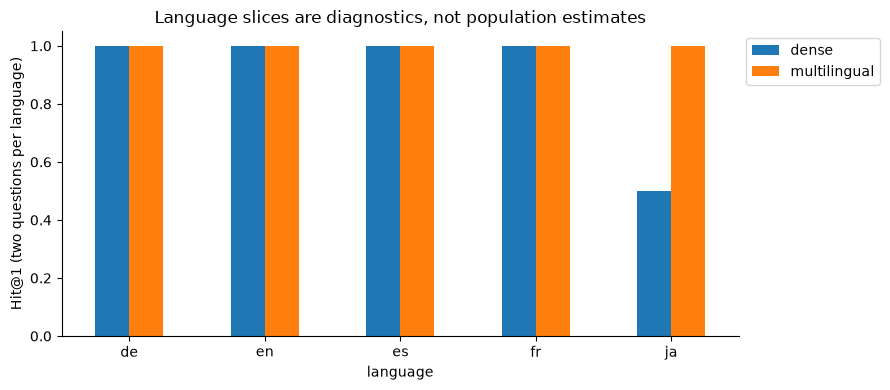

In [2]:
from uuid import uuid4
from vector_masterclass.models import embed
from vector_masterclass.data import documents
from vector_masterclass.chunking import chunk_document
from vector_masterclass.store import VectorIndex
from vector_masterclass.retrieval import exact_search

docs = documents(tenant="public")
ids = [d.key for d in docs]
questions = [
    ("en", "How long is the Atlas warranty?", "atlas-warranty@1"),
    ("en", "What is the Boreal PoE power budget?", "boreal-ports@1"),
    ("es", "¿Cuánto dura la garantía del router Atlas?", "atlas-warranty@1"),
    ("es", "¿Cuál es la potencia total de alimentación por Ethernet de Boreal?", "boreal-ports@1"),
    ("fr", "Quelle est la durée de la garantie du routeur Atlas ?", "atlas-warranty@1"),
    ("fr", "Quelle est la puissance totale PoE du commutateur Boreal ?", "boreal-ports@1"),
    ("de", "Wie lange gilt die Garantie für den Atlas-Router?", "atlas-warranty@1"),
    ("de", "Wie hoch ist das gesamte PoE-Leistungsbudget von Boreal?", "boreal-ports@1"),
    ("ja", "Atlasルーターの保証期間はどのくらいですか？", "atlas-warranty@1"),
    ("ja", "BorealのPoE電力予算は合計何ワットですか？", "boreal-ports@1"),
]
rows = []
for key in ["dense", "multilingual"]:
    vectors = embed([d.text for d in docs], key=key)
    query_vectors = embed([q for lang, q, gold in questions], key=key, role="query")
    for (language, text, gold), vector in zip(questions, query_vectors):
        ranked = [id_ for id_, score in exact_search(vector, vectors, ids, k=3)]
        rows.append(
            {
                "encoder": key,
                "language": language,
                "question": text,
                "top_source": ranked[0],
                "hit_at_1": ranked[0] == gold,
                "recall_at_3": gold in ranked,
            }
        )
index = VectorIndex("vmc_19a_" + uuid4().hex[:8], key="multilingual")
index.create()
rejected = False
try:
    for doc in docs:
        index.upsert(chunk_document(doc, "document"), document_id=doc.id, include_sparse=False)
    server = index.search(questions[-2][1], tenant="public", k=3, exact=True)
    wrong = VectorIndex(index.name, key="dense")
    try:
        wrong.verify_contract()
    except ValueError:
        rejected = True
    finally:
        wrong.close()
    print("Japanese query Qdrant results:", [h.chunk.document_key for h in server])
finally:
    index.drop()
    index.close()
results = lesson.table(pd.DataFrame(rows))
display(results)
fig, ax = plt.subplots(figsize=(9, 4))
results.groupby(["language", "encoder"]).hit_at_1.mean().unstack().plot.bar(ax=ax)
ax.set(
    ylabel="Hit@1 (two questions per language)",
    ylim=(0, 1.05),
    title="Language slices are diagnostics, not population estimates",
)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Interpretation and exercise
A multilingual model can lose to an English model on some queries, and performance can vary sharply by language and domain. Brand names and PoE abbreviations offer shared lexical anchors; easy examples should not be generalized to long legal or technical passages. Translation-based retrieval is another baseline, with its own latency, privacy, and fidelity costs.

**Exercise:** add a query containing a language-specific negation and inspect the retrieved source. Compare token counts against the two model limits. Then attempt to query the multilingual collection using the English model configuration and explain why the representation contract rejects it before relying on dimension validation.

[Multilingual MiniLM model card](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2). Production evaluation needs native-language judgments, scripts, locale-specific terminology, mixed-language queries, and source-language coverage.

In [3]:
manifest = lesson.finish(
    {
        "five_languages": results.language.nunique() == 5,
        "both_encoders_measured": results.encoder.nunique() == 2,
        "equal_dimension_mismatch_rejected": rejected,
        "real_multilingual_qdrant_query": len(server) > 0,
    },
    observations={
        "queries_per_language": 2,
        "judgments": "author-written diagnostic translations; not a representative benchmark",
        "multilingual_model": "pinned local CPU inference",
    },
)

{
  "artifact": "artifacts/20261031T060248Z-1ac835/19a",
  "checks": {
    "five_languages": true,
    "both_encoders_measured": true,
    "equal_dimension_mismatch_rejected": true,
    "real_multilingual_qdrant_query": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.